In [2]:
import torch
import torch.nn as nn
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

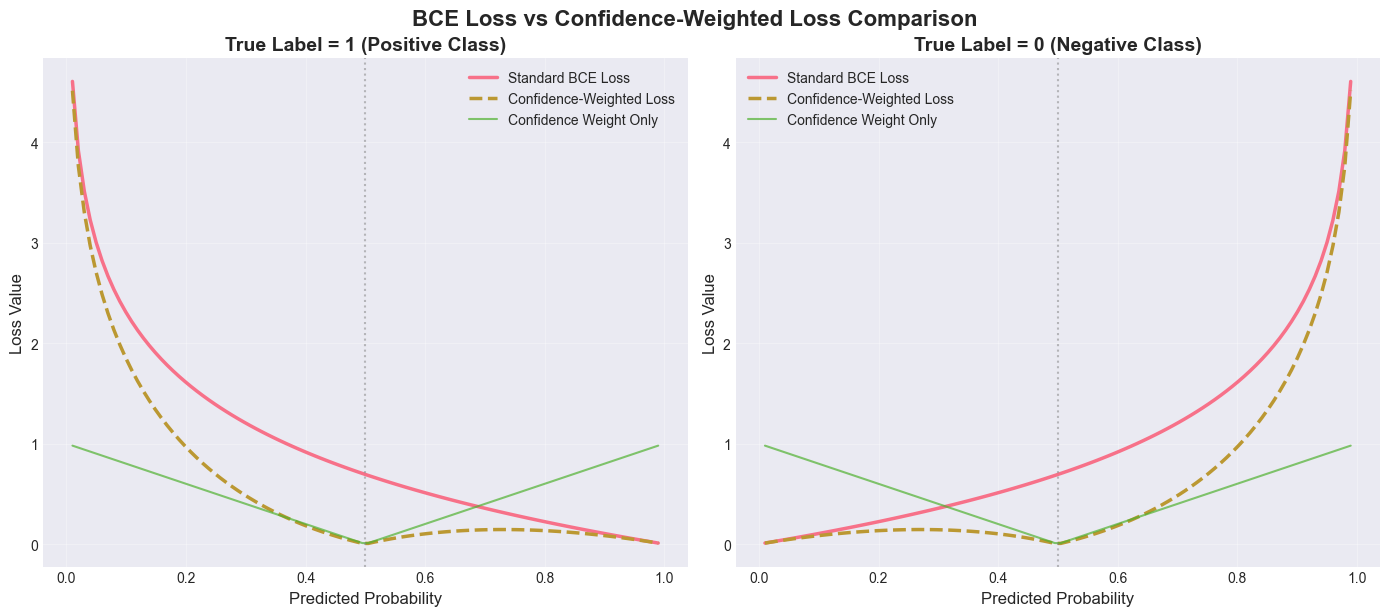

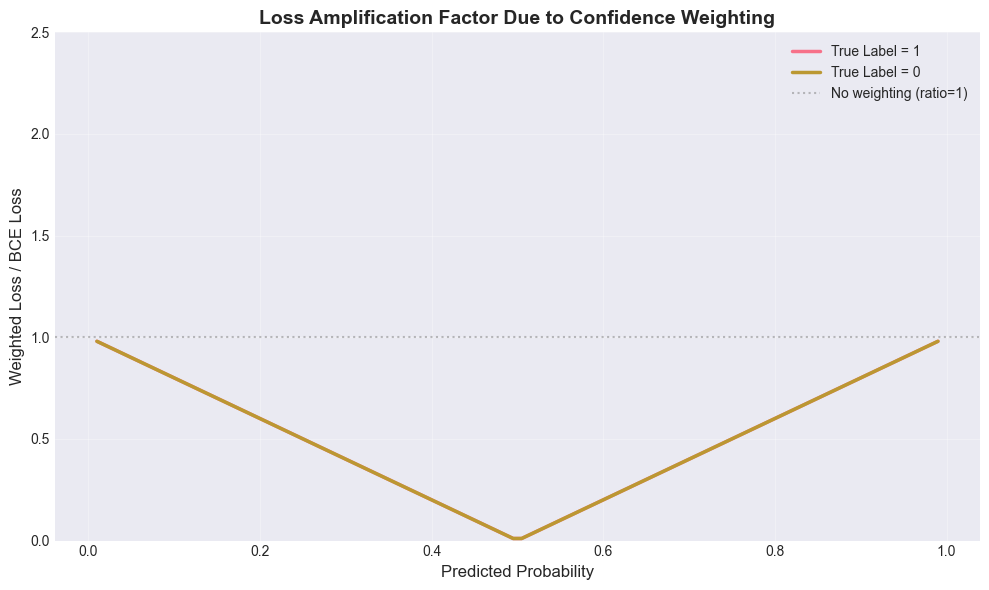

In [3]:

# Set style for better-looking plots
plt.style.use('seaborn-v0_8-darkgrid')
sns.set_palette("husl")

# Define predicted probabilities
pred_probs = np.linspace(0.01, 0.99, 100)

# Convert to logits using inverse sigmoid
logits = np.log(pred_probs / (1 - pred_probs))

# Convert to torch tensors
logits_tensor = torch.tensor(logits, dtype=torch.float32)
pred_probs_tensor = torch.tensor(pred_probs, dtype=torch.float32)

# Initialize BCE loss
bce_loss = nn.BCEWithLogitsLoss(reduction="none")

# Function to calculate confidence weight
def confidence_weight(prob):
    return torch.abs(prob - 0.5) * 2

# Calculate losses for both scenarios
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 6))

# Scenario 1: True Label = 1
true_label_1 = torch.ones_like(logits_tensor)
bce_loss_1 = bce_loss(logits_tensor, true_label_1)
conf_weight_1 = confidence_weight(pred_probs_tensor)
weighted_loss_1 = bce_loss_1 * conf_weight_1

ax1.plot(pred_probs, bce_loss_1.numpy(), label='Standard BCE Loss', linewidth=2.5)
ax1.plot(pred_probs, weighted_loss_1.numpy(), label='Confidence-Weighted Loss', linewidth=2.5, linestyle='--')
ax1.plot(pred_probs, conf_weight_1.numpy(), label='Confidence Weight Only', linewidth=1.5, alpha=0.7)
ax1.set_xlabel('Predicted Probability', fontsize=12)
ax1.set_ylabel('Loss Value', fontsize=12)
ax1.set_title('True Label = 1 (Positive Class)', fontsize=14, fontweight='bold')
ax1.legend()
ax1.grid(True, alpha=0.3)

# Add vertical line at p=0.5
ax1.axvline(x=0.5, color='gray', linestyle=':', alpha=0.5)

# Scenario 2: True Label = 0
true_label_0 = torch.zeros_like(logits_tensor)
bce_loss_0 = bce_loss(logits_tensor, true_label_0)
conf_weight_0 = confidence_weight(pred_probs_tensor)
weighted_loss_0 = bce_loss_0 * conf_weight_0

ax2.plot(pred_probs, bce_loss_0.numpy(), label='Standard BCE Loss', linewidth=2.5)
ax2.plot(pred_probs, weighted_loss_0.numpy(), label='Confidence-Weighted Loss', linewidth=2.5, linestyle='--')
ax2.plot(pred_probs, conf_weight_0.numpy(), label='Confidence Weight Only', linewidth=1.5, alpha=0.7)
ax2.set_xlabel('Predicted Probability', fontsize=12)
ax2.set_ylabel('Loss Value', fontsize=12)
ax2.set_title('True Label = 0 (Negative Class)', fontsize=14, fontweight='bold')
ax2.legend()
ax2.grid(True, alpha=0.3)

# Add vertical line at p=0.5
ax2.axvline(x=0.5, color='gray', linestyle=':', alpha=0.5)

plt.tight_layout()
plt.suptitle('BCE Loss vs Confidence-Weighted Loss Comparison', fontsize=16, fontweight='bold', y=1.02)
plt.show()

# Additional analysis: Loss ratio plot
fig, ax = plt.subplots(1, 1, figsize=(10, 6))

# Calculate ratios (avoiding division by zero)
epsilon = 1e-8
ratio_1 = weighted_loss_1 / (bce_loss_1 + epsilon)
ratio_0 = weighted_loss_0 / (bce_loss_0 + epsilon)

ax.plot(pred_probs, ratio_1.numpy(), label='True Label = 1', linewidth=2.5)
ax.plot(pred_probs, ratio_0.numpy(), label='True Label = 0', linewidth=2.5)
ax.axhline(y=1, color='gray', linestyle=':', alpha=0.5, label='No weighting (ratio=1)')
ax.set_xlabel('Predicted Probability', fontsize=12)
ax.set_ylabel('Weighted Loss / BCE Loss', fontsize=12)
ax.set_title('Loss Amplification Factor Due to Confidence Weighting', fontsize=14, fontweight='bold')
ax.legend()
ax.grid(True, alpha=0.3)
ax.set_ylim(0, 2.5)

plt.tight_layout()
plt.show()

In [4]:
# Detailed analysis at specific probability points
print("Analysis at Key Probability Points:")
print("="*60)

key_probs = [0.1, 0.3, 0.5, 0.7, 0.9]
for p in key_probs:
    idx = np.argmin(np.abs(pred_probs - p))
    
    print(f"\nPredicted Probability: {p}")
    print("-"*30)
    
    # For true label = 1
    bce_1 = bce_loss_1[idx].item()
    weight_1 = conf_weight_1[idx].item()
    weighted_1 = weighted_loss_1[idx].item()
    
    print(f"True Label = 1:")
    print(f"  BCE Loss: {bce_1:.4f}")
    print(f"  Confidence Weight: {weight_1:.4f}")
    print(f"  Weighted Loss: {weighted_1:.4f}")
    print(f"  Amplification: {weighted_1/bce_1:.2f}x")
    
    # For true label = 0
    bce_0 = bce_loss_0[idx].item()
    weight_0 = conf_weight_0[idx].item()
    weighted_0 = weighted_loss_0[idx].item()
    
    print(f"True Label = 0:")
    print(f"  BCE Loss: {bce_0:.4f}")
    print(f"  Confidence Weight: {weight_0:.4f}")
    print(f"  Weighted Loss: {weighted_0:.4f}")
    print(f"  Amplification: {weighted_0/bce_0:.2f}x")

Analysis at Key Probability Points:

Predicted Probability: 0.1
------------------------------
True Label = 1:
  BCE Loss: 2.3117
  Confidence Weight: 0.8018
  Weighted Loss: 1.8536
  Amplification: 0.80x
True Label = 0:
  BCE Loss: 0.1044
  Confidence Weight: 0.8018
  Weighted Loss: 0.0837
  Amplification: 0.80x

Predicted Probability: 0.3
------------------------------
True Label = 1:
  BCE Loss: 1.2138
  Confidence Weight: 0.4059
  Weighted Loss: 0.4926
  Amplification: 0.41x
True Label = 0:
  BCE Loss: 0.3525
  Confidence Weight: 0.4059
  Weighted Loss: 0.1431
  Amplification: 0.41x

Predicted Probability: 0.5
------------------------------
True Label = 1:
  BCE Loss: 0.6833
  Confidence Weight: 0.0099
  Weighted Loss: 0.0068
  Amplification: 0.01x
True Label = 0:
  BCE Loss: 0.7031
  Confidence Weight: 0.0099
  Weighted Loss: 0.0070
  Amplification: 0.01x

Predicted Probability: 0.7
------------------------------
True Label = 1:
  BCE Loss: 0.3525
  Confidence Weight: 0.4059
  Wei

In [5]:
import torch
import torch.nn as nn
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib import cm
from mpl_toolkits.mplot3d import Axes3D


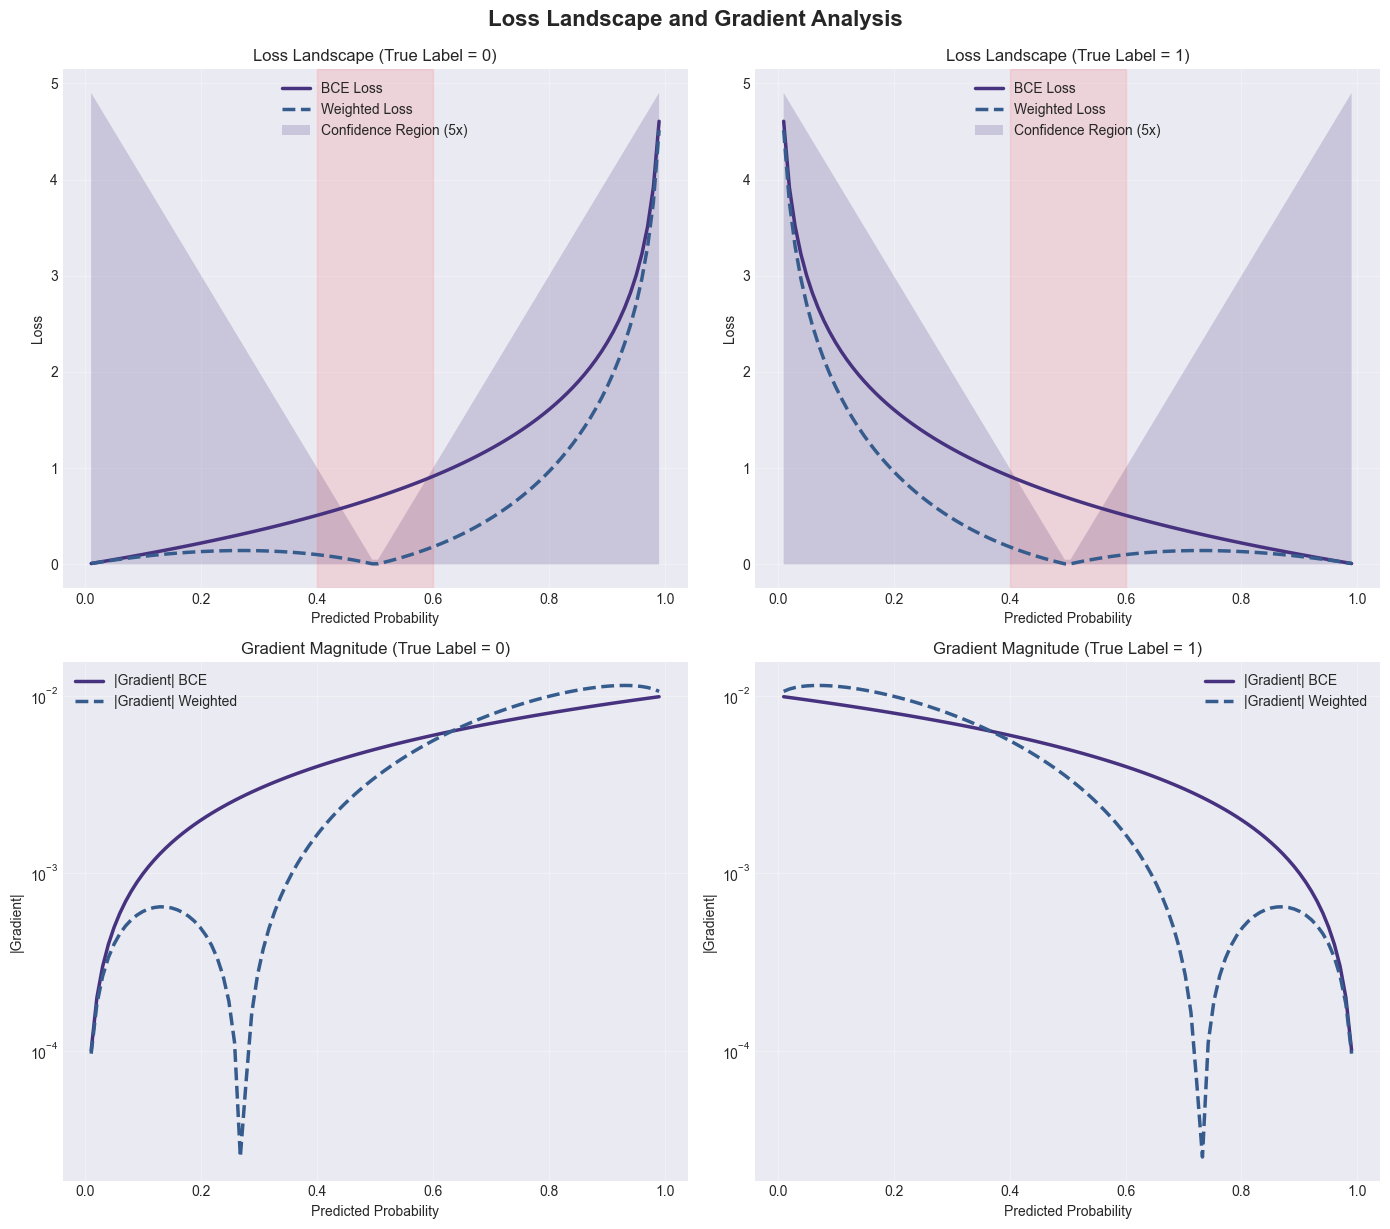

In [6]:

# Set style
plt.style.use('seaborn-v0_8-darkgrid')
sns.set_palette("viridis")

# Helper functions
def inverse_sigmoid(p):
    """Convert probability to logit"""
    p = np.clip(p, 1e-7, 1-1e-7)  # Avoid numerical issues
    return np.log(p / (1 - p))

def confidence_weight(prob):
    """Calculate confidence weight"""
    return np.abs(prob - 0.5) * 2

def calculate_gradient(logits, targets, use_confidence_weight=False):
    """Calculate gradient of loss w.r.t. logits"""
    logits_tensor = torch.tensor(logits, dtype=torch.float32, requires_grad=True)
    targets_tensor = torch.tensor(targets, dtype=torch.float32)
    
    bce_loss = nn.BCEWithLogitsLoss(reduction="none")
    loss = bce_loss(logits_tensor, targets_tensor)
    
    if use_confidence_weight:
        probs = torch.sigmoid(logits_tensor)
        conf_weight = torch.abs(probs - 0.5) * 2
        loss = loss * conf_weight
    
    loss.mean().backward()
    return logits_tensor.grad.numpy()

# Visualization 1: Loss Landscape Comparison
fig, axes = plt.subplots(2, 2, figsize=(14, 12))

pred_probs = np.linspace(0.01, 0.99, 100)
logits = inverse_sigmoid(pred_probs)

# Calculate losses and gradients for both true labels
for i, true_label in enumerate([0, 1]):
    # Standard BCE
    targets = np.full_like(pred_probs, true_label)
    bce_loss_vals = -targets * np.log(pred_probs) - (1-targets) * np.log(1-pred_probs)
    
    # Confidence-weighted
    conf_weights = confidence_weight(pred_probs)
    weighted_loss_vals = bce_loss_vals * conf_weights
    
    # Gradients
    grad_bce = calculate_gradient(logits, targets, use_confidence_weight=False)
    grad_weighted = calculate_gradient(logits, targets, use_confidence_weight=True)
    
    # Plot losses
    ax = axes[0, i]
    ax.plot(pred_probs, bce_loss_vals, label='BCE Loss', linewidth=2.5)
    ax.plot(pred_probs, weighted_loss_vals, label='Weighted Loss', linewidth=2.5, linestyle='--')
    ax.fill_between(pred_probs, 0, conf_weights*5, alpha=0.2, label='Confidence Region (5x)')
    ax.set_xlabel('Predicted Probability')
    ax.set_ylabel('Loss')
    ax.set_title(f'Loss Landscape (True Label = {true_label})')
    ax.legend()
    ax.grid(True, alpha=0.3)
    
    # Highlight "safe zone" around 0.5
    ax.axvspan(0.4, 0.6, alpha=0.1, color='red', label='Low confidence zone')
    
    # Plot gradients
    ax = axes[1, i]
    ax.plot(pred_probs, np.abs(grad_bce), label='|Gradient| BCE', linewidth=2.5)
    ax.plot(pred_probs, np.abs(grad_weighted), label='|Gradient| Weighted', linewidth=2.5, linestyle='--')
    ax.set_xlabel('Predicted Probability')
    ax.set_ylabel('|Gradient|')
    ax.set_title(f'Gradient Magnitude (True Label = {true_label})')
    ax.legend()
    ax.grid(True, alpha=0.3)
    ax.set_yscale('log')

plt.tight_layout()
plt.suptitle('Loss Landscape and Gradient Analysis', fontsize=16, fontweight='bold', y=1.02)
plt.show()

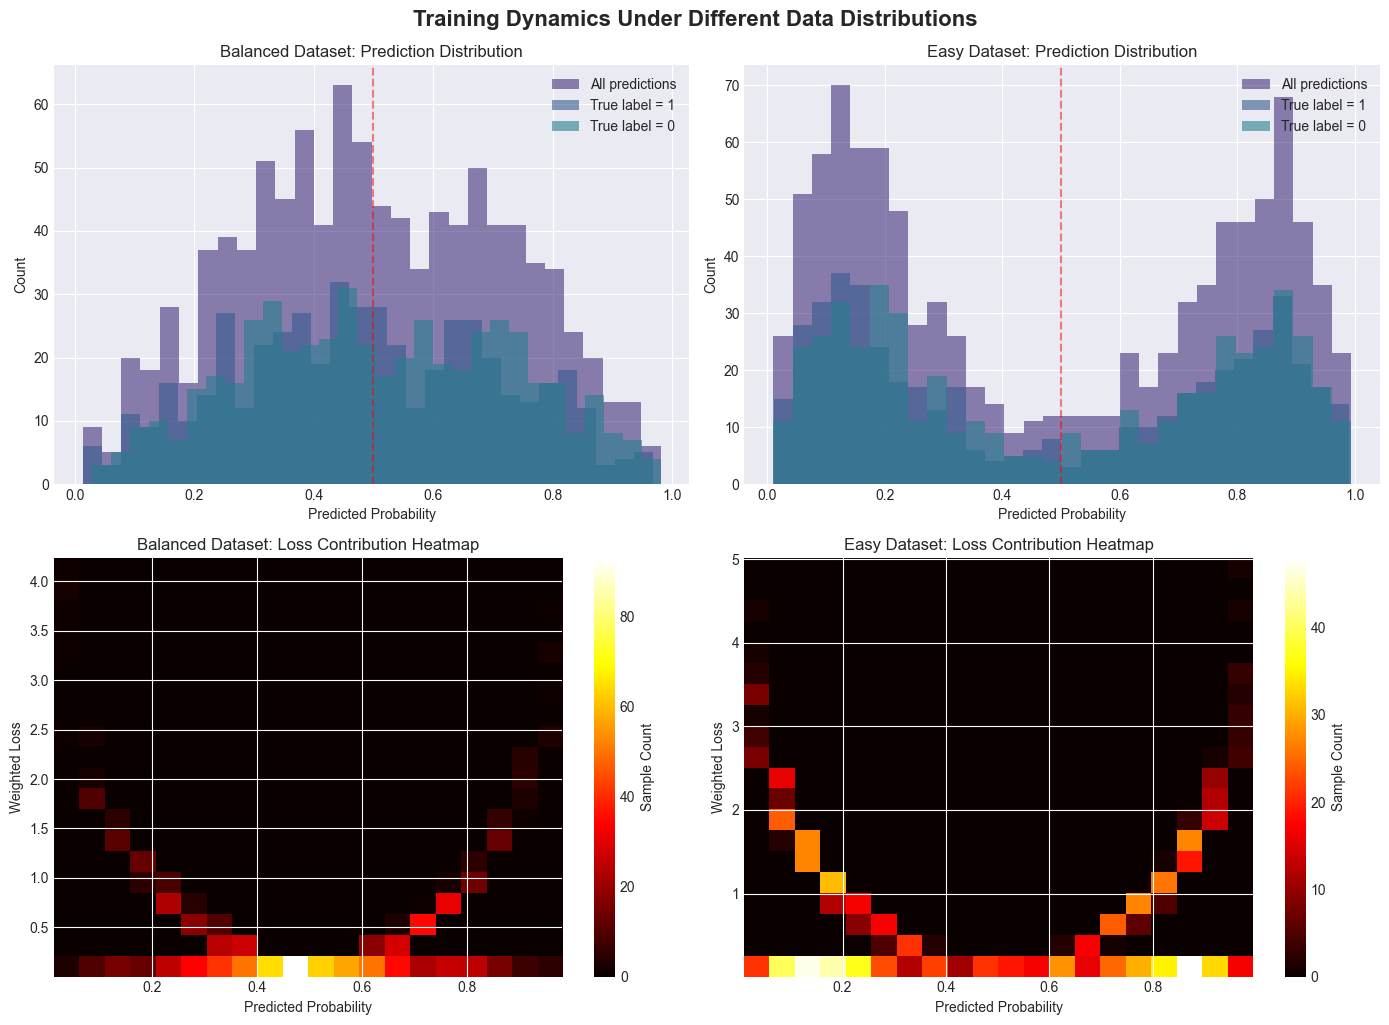

In [7]:

# Visualization 2: Training Dynamics Simulation
fig, axes = plt.subplots(2, 2, figsize=(14, 10))

# Simulate different training scenarios
np.random.seed(42)

# Scenario 1: Balanced dataset with mixed difficulty
n_samples = 1000
scenarios = {
    'Balanced Dataset': {
        'true_labels': np.random.binomial(1, 0.5, n_samples),
        'initial_probs': np.random.beta(2, 2, n_samples),  # Centered around 0.5
    },
    'Easy Dataset': {
        'true_labels': np.random.binomial(1, 0.5, n_samples),
        'initial_probs': np.where(
            np.random.binomial(1, 0.5, n_samples),
            np.random.beta(8, 2, n_samples),  # High prob for label=1
            np.random.beta(2, 8, n_samples)   # Low prob for label=0
        ),
    }
}

for idx, (scenario_name, scenario_data) in enumerate(scenarios.items()):
    true_labels = scenario_data['true_labels']
    initial_probs = scenario_data['initial_probs']
    
    # Calculate losses
    logits = inverse_sigmoid(initial_probs)
    bce_losses = -true_labels * np.log(initial_probs) - (1-true_labels) * np.log(1-initial_probs)
    conf_weights = confidence_weight(initial_probs)
    weighted_losses = bce_losses * conf_weights
    
    # Plot distribution of predictions
    ax = axes[0, idx]
    ax.hist(initial_probs, bins=30, alpha=0.6, label='All predictions')
    ax.hist(initial_probs[true_labels == 1], bins=30, alpha=0.6, label='True label = 1')
    ax.hist(initial_probs[true_labels == 0], bins=30, alpha=0.6, label='True label = 0')
    ax.set_xlabel('Predicted Probability')
    ax.set_ylabel('Count')
    ax.set_title(f'{scenario_name}: Prediction Distribution')
    ax.legend()
    ax.axvline(0.5, color='red', linestyle='--', alpha=0.5)
    
    # Plot loss contributions
    ax = axes[1, idx]
    
    # Create 2D histogram showing where losses come from
    hist, xedges, yedges = np.histogram2d(initial_probs, weighted_losses, bins=20)
    extent = [xedges[0], xedges[-1], yedges[0], yedges[-1]]
    
    im = ax.imshow(hist.T, origin='lower', extent=extent, aspect='auto', cmap='hot')
    ax.set_xlabel('Predicted Probability')
    ax.set_ylabel('Weighted Loss')
    ax.set_title(f'{scenario_name}: Loss Contribution Heatmap')
    plt.colorbar(im, ax=ax, label='Sample Count')

plt.tight_layout()
plt.suptitle('Training Dynamics Under Different Data Distributions', fontsize=16, fontweight='bold', y=1.02)
plt.show()


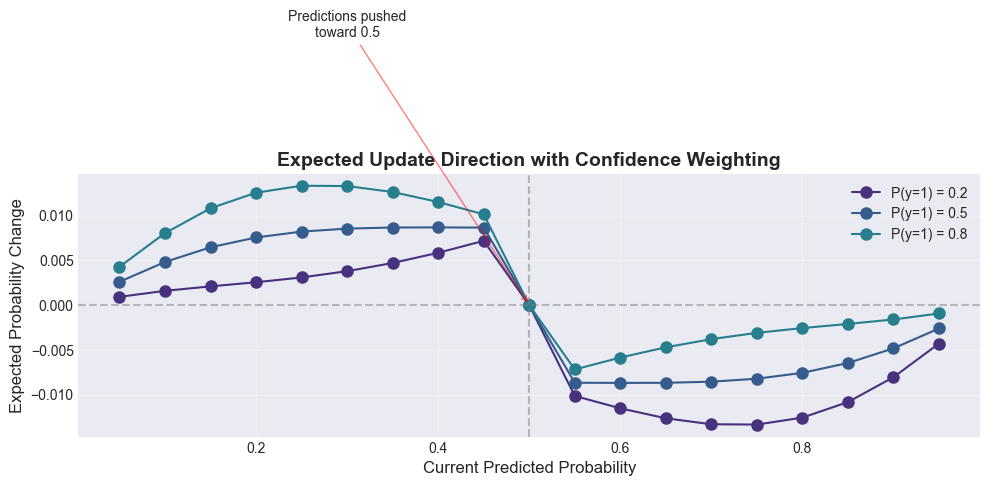

In [8]:

# Visualization 3: Expected Update Direction
fig, ax = plt.subplots(1, 1, figsize=(10, 6))

# For different predicted probabilities, show the expected gradient direction
pred_probs_range = np.linspace(0.05, 0.95, 19)
true_label_probs = [0.2, 0.5, 0.8]  # Different class balance scenarios

for true_prob in true_label_probs:
    expected_updates = []
    
    for pred_prob in pred_probs_range:
        logit = inverse_sigmoid(pred_prob)
        
        # Expected gradient = P(y=1) * grad(y=1) + P(y=0) * grad(y=0)
        grad_if_true_1 = calculate_gradient(np.array([logit]), np.array([1.0]), use_confidence_weight=True)[0]
        grad_if_true_0 = calculate_gradient(np.array([logit]), np.array([0.0]), use_confidence_weight=True)[0]
        
        expected_grad = true_prob * grad_if_true_1 + (1 - true_prob) * grad_if_true_0
        expected_updates.append(expected_grad)
    
    # Convert gradient to change in probability
    prob_changes = []
    for i, grad in enumerate(expected_updates):
        # Approximate change in probability using gradient
        p = pred_probs_range[i]
        dp_dlogit = p * (1 - p)  # Derivative of sigmoid
        prob_change = -grad * dp_dlogit * 0.1  # Negative because we descend, 0.1 is learning rate
        prob_changes.append(prob_change)
    
    ax.plot(pred_probs_range, prob_changes, 'o-', label=f'P(y=1) = {true_prob}', markersize=8)

ax.axhline(0, color='gray', linestyle='--', alpha=0.5)
ax.axvline(0.5, color='gray', linestyle='--', alpha=0.5)
ax.set_xlabel('Current Predicted Probability', fontsize=12)
ax.set_ylabel('Expected Probability Change', fontsize=12)
ax.set_title('Expected Update Direction with Confidence Weighting', fontsize=14, fontweight='bold')
ax.legend()
ax.grid(True, alpha=0.3)

# Add annotations
ax.annotate('Predictions pushed\ntoward 0.5', xy=(0.5, 0), xytext=(0.3, 0.03),
            arrowprops=dict(arrowstyle='->', color='red', alpha=0.5),
            fontsize=10, ha='center')

plt.tight_layout()
plt.show()


In [9]:

# Summary Analysis
print("\nKey Insights from the Visualizations:")
print("="*60)
print("\n1. LOSS LANDSCAPE EFFECTS:")
print("   - Confidence weighting creates a 'valley' around p=0.5")
print("   - This can act as an attractor for uncertain predictions")
print("   - Confident wrong predictions face dramatically higher losses")

print("\n2. GRADIENT BEHAVIOR:")
print("   - Near p=0.5: Gradients are suppressed (smaller updates)")
print("   - Far from p=0.5: Gradients are amplified (larger updates)")
print("   - This creates a 'safe zone' around p=0.5 where model updates are minimal")

print("\n3. POTENTIAL OUTCOMES:")
print("   a) Cautious Model: If many examples are hard to classify,")
print("      predictions may cluster around 0.5 to minimize weighted loss")
print("   b) Overconfident Model: If most examples are easy and correctly")
print("      classified with high confidence, the model learns to be very decisive")

print("\n4. RECOMMENDATIONS:")
print("   - Monitor prediction distribution during training")
print("   - Consider adaptive confidence weighting that changes over epochs")
print("   - Use with label smoothing to prevent extreme overconfidence")
print("   - Start with small weight factors and increase gradually")


Key Insights from the Visualizations:

1. LOSS LANDSCAPE EFFECTS:
   - Confidence weighting creates a 'valley' around p=0.5
   - This can act as an attractor for uncertain predictions
   - Confident wrong predictions face dramatically higher losses

2. GRADIENT BEHAVIOR:
   - Near p=0.5: Gradients are suppressed (smaller updates)
   - Far from p=0.5: Gradients are amplified (larger updates)
   - This creates a 'safe zone' around p=0.5 where model updates are minimal

3. POTENTIAL OUTCOMES:
   a) Cautious Model: If many examples are hard to classify,
      predictions may cluster around 0.5 to minimize weighted loss
   b) Overconfident Model: If most examples are easy and correctly
      classified with high confidence, the model learns to be very decisive

4. RECOMMENDATIONS:
   - Monitor prediction distribution during training
   - Consider adaptive confidence weighting that changes over epochs
   - Use with label smoothing to prevent extreme overconfidence
   - Start with small weig

In [10]:
import torch
import torch.nn as nn
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib.patches import Rectangle


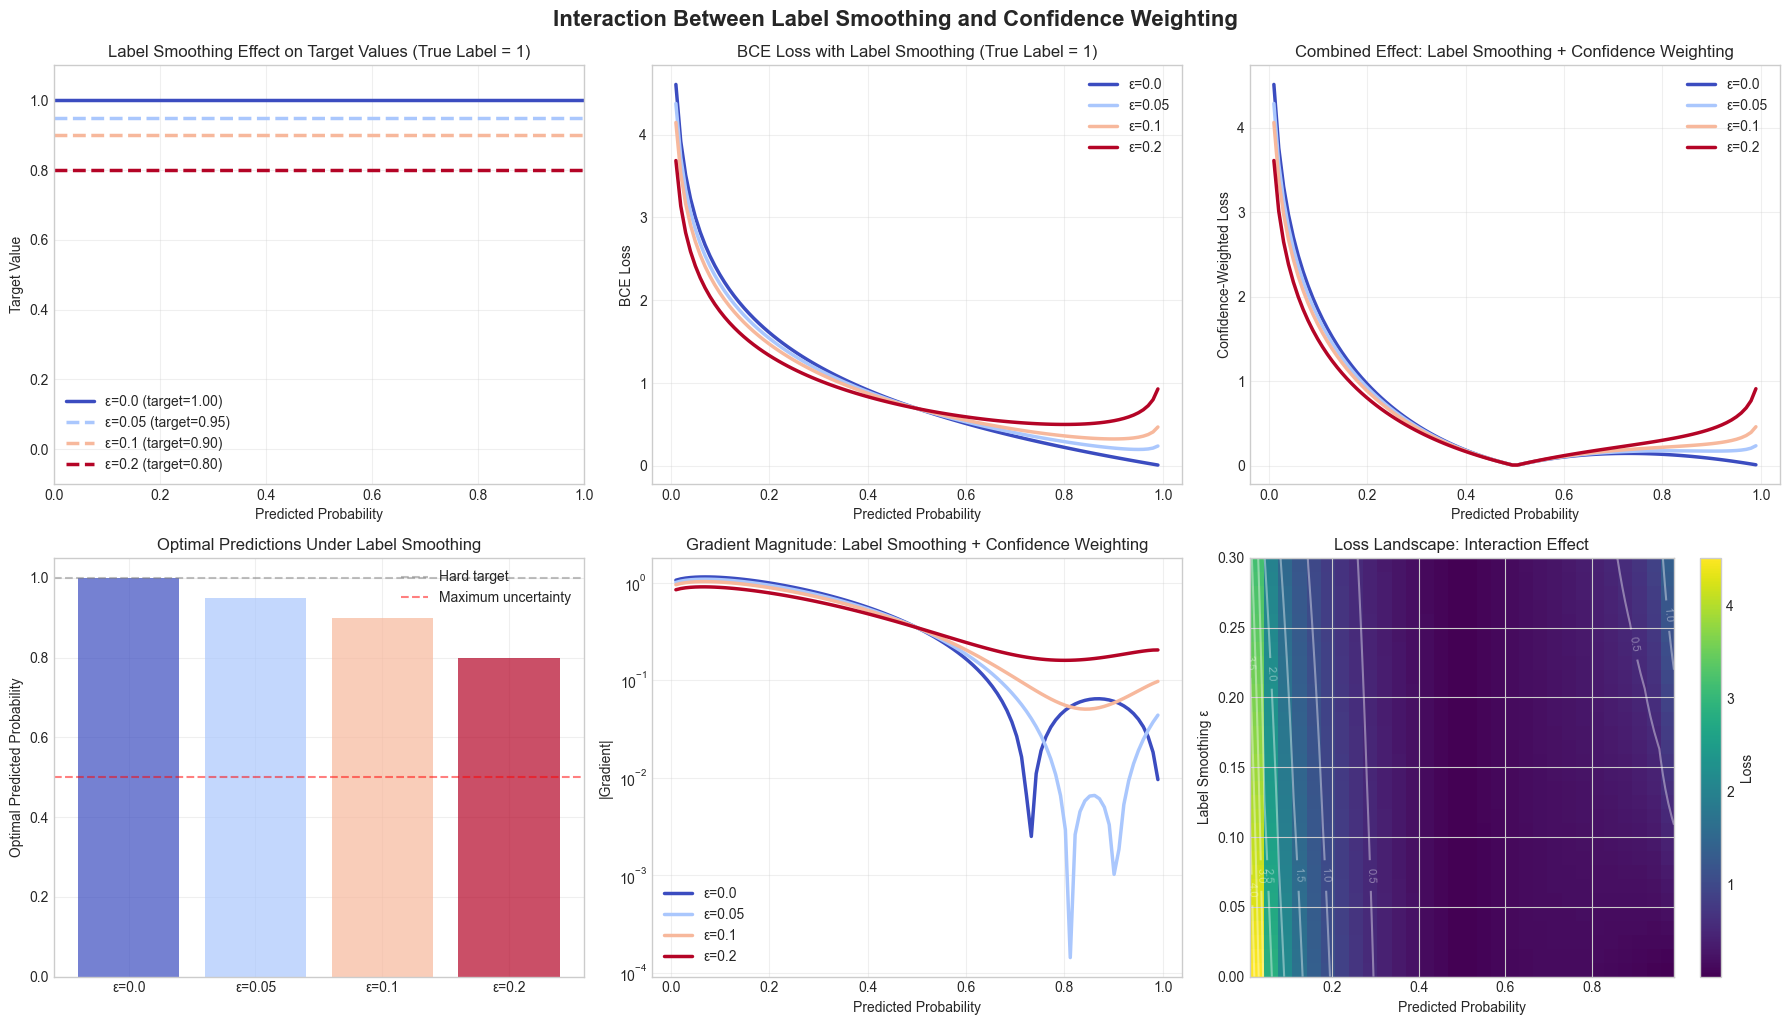

In [12]:

# Set style
plt.style.use('seaborn-v0_8-whitegrid')
sns.set_palette("Set2")

def inverse_sigmoid(p):
    """Convert probability to logit"""
    p = np.clip(p, 1e-7, 1-1e-7)
    return np.log(p / (1 - p))

def apply_label_smoothing(target, epsilon):
    """Apply label smoothing to target"""
    return target * (1 - epsilon) + (1 - target) * epsilon

def confidence_weight(prob):
    """Calculate confidence weight"""
    return np.abs(prob - 0.5) * 2

# Create visualization comparing different epsilon values
fig, axes = plt.subplots(2, 3, figsize=(18, 10))
axes = axes.flatten()

# Parameters
pred_probs = np.linspace(0.01, 0.99, 100)
logits = inverse_sigmoid(pred_probs)
epsilon_values = [0.0, 0.05, 0.1, 0.2]
true_label = 1  # Focus on positive class for clarity

# Color map for epsilon values
colors = plt.cm.coolwarm(np.linspace(0, 1, len(epsilon_values)))

# Plot 1: Effect on target values
ax = axes[0]
for eps, color in zip(epsilon_values, colors):
    smoothed_target = apply_label_smoothing(true_label, eps)
    ax.axhline(smoothed_target, label=f'ε={eps} (target={smoothed_target:.2f})', 
               color=color, linewidth=2.5, linestyle='--' if eps > 0 else '-')
ax.set_ylim(-0.1, 1.1)
ax.set_xlabel('Predicted Probability')
ax.set_ylabel('Target Value')
ax.set_title('Label Smoothing Effect on Target Values (True Label = 1)')
ax.legend()
ax.grid(True, alpha=0.3)

# Plot 2: BCE Loss with different smoothing levels
ax = axes[1]
for eps, color in zip(epsilon_values, colors):
    smoothed_target = apply_label_smoothing(true_label, eps)
    bce_loss = -smoothed_target * np.log(pred_probs) - (1-smoothed_target) * np.log(1-pred_probs)
    ax.plot(pred_probs, bce_loss, label=f'ε={eps}', color=color, linewidth=2.5)
ax.set_xlabel('Predicted Probability')
ax.set_ylabel('BCE Loss')
ax.set_title('BCE Loss with Label Smoothing (True Label = 1)')
ax.legend()
ax.grid(True, alpha=0.3)

# Plot 3: Combined effect with confidence weighting
ax = axes[2]
conf_weights = confidence_weight(pred_probs)
for eps, color in zip(epsilon_values, colors):
    smoothed_target = apply_label_smoothing(true_label, eps)
    bce_loss = -smoothed_target * np.log(pred_probs) - (1-smoothed_target) * np.log(1-pred_probs)
    weighted_loss = bce_loss * conf_weights
    ax.plot(pred_probs, weighted_loss, label=f'ε={eps}', color=color, linewidth=2.5)
ax.set_xlabel('Predicted Probability')
ax.set_ylabel('Confidence-Weighted Loss')
ax.set_title('Combined Effect: Label Smoothing + Confidence Weighting')
ax.legend()
ax.grid(True, alpha=0.3)

# Plot 4: Optimal prediction under different smoothing
ax = axes[3]
optimal_probs = []
for eps in epsilon_values:
    # The optimal prediction minimizes the loss
    # For label smoothing, this is when pred_prob = smoothed_target
    smoothed_target = apply_label_smoothing(true_label, eps)
    optimal_probs.append(smoothed_target)

ax.bar(range(len(epsilon_values)), optimal_probs, color=colors, alpha=0.7)
ax.set_xticks(range(len(epsilon_values)))
ax.set_xticklabels([f'ε={eps}' for eps in epsilon_values])
ax.set_ylabel('Optimal Predicted Probability')
ax.set_title('Optimal Predictions Under Label Smoothing')
ax.axhline(1.0, color='gray', linestyle='--', alpha=0.5, label='Hard target')
ax.axhline(0.5, color='red', linestyle='--', alpha=0.5, label='Maximum uncertainty')
ax.legend()
ax.grid(True, alpha=0.3)

# Plot 5: Gradient comparison
ax = axes[4]
logits_tensor = torch.tensor(logits, dtype=torch.float32)
for eps, color in zip(epsilon_values, colors):
    gradients = []
    for logit in logits:
        logit_tensor = torch.tensor([logit], dtype=torch.float32, requires_grad=True)
        prob = torch.sigmoid(logit_tensor)
        
        smoothed_target = apply_label_smoothing(true_label, eps)
        loss = -smoothed_target * torch.log(prob) - (1-smoothed_target) * torch.log(1-prob)
        
        # Apply confidence weighting
        conf_weight = torch.abs(prob - 0.5) * 2
        weighted_loss = loss * conf_weight
        
        weighted_loss.backward()
        gradients.append(logit_tensor.grad.item())
    
    ax.plot(pred_probs, np.abs(gradients), label=f'ε={eps}', color=color, linewidth=2.5)

ax.set_xlabel('Predicted Probability')
ax.set_ylabel('|Gradient|')
ax.set_title('Gradient Magnitude: Label Smoothing + Confidence Weighting')
ax.legend()
ax.grid(True, alpha=0.3)
ax.set_yscale('log')

# Plot 6: 2D heatmap of loss landscape
ax = axes[5]
eps_range = np.linspace(0, 0.3, 30)
prob_range = np.linspace(0.01, 0.99, 30)
loss_landscape = np.zeros((len(eps_range), len(prob_range)))

for i, eps in enumerate(eps_range):
    for j, prob in enumerate(prob_range):
        smoothed_target = apply_label_smoothing(true_label, eps)
        bce_loss = -smoothed_target * np.log(prob) - (1-smoothed_target) * np.log(1-prob)
        conf_weight = confidence_weight(prob)
        loss_landscape[i, j] = bce_loss * conf_weight

im = ax.imshow(loss_landscape, aspect='auto', origin='lower', cmap='viridis',
               extent=[prob_range[0], prob_range[-1], eps_range[0], eps_range[-1]])
ax.set_xlabel('Predicted Probability')
ax.set_ylabel('Label Smoothing ε')
ax.set_title('Loss Landscape: Interaction Effect')
plt.colorbar(im, ax=ax, label='Loss')

# Add contour lines
contours = ax.contour(prob_range, eps_range, loss_landscape, levels=10, colors='white', alpha=0.4)
ax.clabel(contours, inline=True, fontsize=8)

plt.tight_layout()
plt.suptitle('Interaction Between Label Smoothing and Confidence Weighting', 
             fontsize=16, fontweight='bold', y=1.02)
plt.show()



Interaction Effects Analysis:

Label Smoothing ε = 0.0:
----------------------------------------
Smoothed target value: 1.000
Minimum gradient at p = 0.733
Loss at p=0.5: 0.000
Loss at p=0.9: 0.084

Label Smoothing ε = 0.05:
----------------------------------------
Smoothed target value: 0.950
Minimum gradient at p = 0.812
Loss at p=0.5: 0.000
Loss at p=0.9: 0.172

Label Smoothing ε = 0.1:
----------------------------------------
Smoothed target value: 0.900
Minimum gradient at p = 0.842
Loss at p=0.5: 0.000
Loss at p=0.9: 0.260

Label Smoothing ε = 0.2:
----------------------------------------
Smoothed target value: 0.800
Minimum gradient at p = 0.802
Loss at p=0.5: 0.000
Loss at p=0.9: 0.436


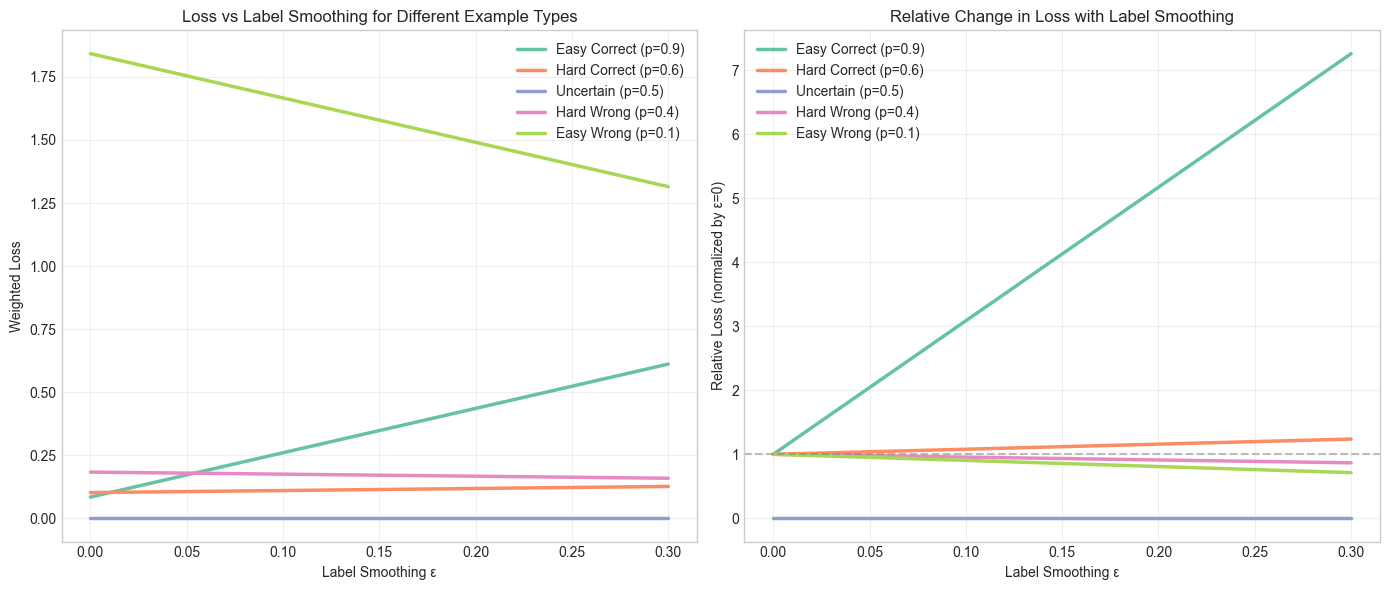

In [13]:

# Analysis of the interaction effects
print("\nInteraction Effects Analysis:")
print("="*60)

# Calculate some key metrics
for eps in [0.0, 0.05, 0.1, 0.2]:
    print(f"\nLabel Smoothing ε = {eps}:")
    print("-"*40)
    
    smoothed_target = apply_label_smoothing(true_label, eps)
    print(f"Smoothed target value: {smoothed_target:.3f}")
    
    # Find where gradient is minimal (excluding p=smoothed_target)
    gradients = []
    for p in pred_probs:
        logit = inverse_sigmoid(p)
        logit_tensor = torch.tensor([logit], dtype=torch.float32, requires_grad=True)
        prob = torch.sigmoid(logit_tensor)
        
        loss = -smoothed_target * torch.log(prob) - (1-smoothed_target) * torch.log(1-prob)
        conf_weight = torch.abs(prob - 0.5) * 2
        weighted_loss = loss * conf_weight
        
        weighted_loss.backward()
        gradients.append(abs(logit_tensor.grad.item()))
    
    min_grad_idx = np.argmin(gradients)
    min_grad_prob = pred_probs[min_grad_idx]
    
    print(f"Minimum gradient at p = {min_grad_prob:.3f}")
    print(f"Loss at p=0.5: {(-smoothed_target * np.log(0.5) - (1-smoothed_target) * np.log(0.5)) * confidence_weight(0.5):.3f}")
    print(f"Loss at p=0.9: {(-smoothed_target * np.log(0.9) - (1-smoothed_target) * np.log(0.1)) * confidence_weight(0.9):.3f}")


In [ ]:

# Additional visualization: Effect on different types of examples
fig, axes = plt.subplots(1, 2, figsize=(14, 6))

# Define example types
example_types = {
    'Easy Correct': {'true_label': 1, 'pred_prob': 0.9},
    'Hard Correct': {'true_label': 1, 'pred_prob': 0.6},
    'Uncertain': {'true_label': 1, 'pred_prob': 0.5},
    'Hard Wrong': {'true_label': 1, 'pred_prob': 0.4},
    'Easy Wrong': {'true_label': 1, 'pred_prob': 0.1},
}

eps_range = np.linspace(0, 0.3, 50)

# Plot loss for each example type
ax = axes[0]
for name, example in example_types.items():
    losses = []
    for eps in eps_range:
        smoothed_target = apply_label_smoothing(example['true_label'], eps)
        bce_loss = -smoothed_target * np.log(example['pred_prob']) - \
                   (1-smoothed_target) * np.log(1-example['pred_prob'])
        conf_weight = confidence_weight(example['pred_prob'])
        weighted_loss = bce_loss * conf_weight
        losses.append(weighted_loss)
    
    ax.plot(eps_range, losses, label=f"{name} (p={example['pred_prob']})", linewidth=2.5)

ax.set_xlabel('Label Smoothing ε')
ax.set_ylabel('Weighted Loss')
ax.set_title('Loss vs Label Smoothing for Different Example Types')
ax.legend()
ax.grid(True, alpha=0.3)

# Plot relative change in loss
ax = axes[1]
for name, example in example_types.items():
    losses = []
    for eps in eps_range:
        smoothed_target = apply_label_smoothing(example['true_label'], eps)
        bce_loss = -smoothed_target * np.log(example['pred_prob']) - \
                   (1-smoothed_target) * np.log(1-example['pred_prob'])
        conf_weight = confidence_weight(example['pred_prob'])
        weighted_loss = bce_loss * conf_weight
        losses.append(weighted_loss)
    
    # Normalize by loss at eps=0
    base_loss = losses[0]
    relative_losses = [l/base_loss if base_loss > 0 else 0 for l in losses]
    
    ax.plot(eps_range, relative_losses, label=f"{name} (p={example['pred_prob']})", linewidth=2.5)

ax.set_xlabel('Label Smoothing ε')
ax.set_ylabel('Relative Loss (normalized by ε=0)')
ax.set_title('Relative Change in Loss with Label Smoothing')
ax.legend()
ax.grid(True, alpha=0.3)
ax.axhline(1.0, color='gray', linestyle='--', alpha=0.5)

plt.tight_layout()
plt.show()


In [ ]:

print("\n\nKey Insights on Label Smoothing + Confidence Weighting Interaction:")
print("="*70)
print("\n1. COMPLEMENTARY EFFECTS:")
print("   - Label smoothing prevents extreme confidence (p→1.0)")
print("   - Confidence weighting de-emphasizes uncertain predictions (p→0.5)")
print("   - Together, they create a 'sweet spot' around p=0.7-0.9 for positive examples")

print("\n2. MITIGATION OF OVERCONFIDENCE:")
print("   - Label smoothing directly addresses the overconfidence concern")
print("   - Even with confidence weighting, the model can't achieve zero loss")
print("   - This prevents the model from learning to output extreme logits")

print("\n3. GRADIENT BEHAVIOR:")
print("   - Without smoothing: Gradients → 0 as p → 1 (saturation)")
print("   - With smoothing: Gradients remain non-zero even at high confidence")
print("   - Confidence weighting amplifies these non-zero gradients")

print("\n4. PRACTICAL IMPLICATIONS:")
print("   - Start with small ε (0.05-0.1) to avoid over-regularization")
print("   - Monitor both prediction distribution AND loss distribution")
print("   - Consider scheduling: increase ε if model becomes overconfident")
print("   - The combination is self-regulating to some extent")